In [32]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer


In [33]:
df = pd.read_csv('titanic.csv', usecols=['Age', 'Fare', 'Survived'])


In [34]:
df.dropna(inplace=True)

In [35]:
df.shape

(714, 3)

In [36]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


# without applying binning 

In [37]:
x = df.iloc[:,1:]
y = df.iloc[:,0]

In [38]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [39]:
x_train.head()

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000
719,33.0,7.7750
666,25.0,13.0000


In [40]:
clf = DecisionTreeClassifier()

In [41]:
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

In [42]:
accuracy_score(y_test, y_pred)

0.6363636363636364

In [43]:
np.mean(cross_val_score(DecisionTreeClassifier(), x, y, cv=10, scoring='accuracy'))

np.float64(0.6317097026604068)

In [44]:
kbin_age = KBinsDiscretizer(n_bins=15, encode='ordinal', strategy='quantile')  #kmeans,uniform, quintaile
kbin_fare = KBinsDiscretizer(n_bins=15, encode='ordinal', strategy='quantile')

In [45]:
trf = ColumnTransformer([
    ('first', kbin_age, [0]),   # index [0] hai  age ka 
    ('second', kbin_fare, [1])
])

In [46]:
x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


In [47]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=15),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=15)}

In [48]:
# trf.named_transformers_['first'].n_bins_
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [49]:
output = pd.DataFrame({
    'age': x_train['Age'],
    'age_trf': x_train_trf[:, 0],
    'fare': x_train['Fare'],
    'fare_trf': x_train_trf[:, 1]
})

In [50]:
output['age_labels'] = pd.cut(x=x_train['Age'],
                              bins=trf.named_transformers_['first'].bin_edges_[0].tolist())

output['fare_labels'] = pd.cut(x=x_train['Fare'],
                              bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [51]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
325,36.00,10.0,135.6333,14.0,"(35.0, 38.0]","(108.9, 512.329]"
786,18.00,2.0,7.4958,1.0,"(16.0, 19.0]","(7.25, 7.775]"
577,39.00,11.0,55.9000,12.0,"(38.0, 42.0]","(51.479, 76.292]"
644,0.75,0.0,19.2583,8.0,"(0.42, 6.0]","(18.75, 26.0]"
385,18.00,2.0,73.5000,12.0,"(16.0, 19.0]","(51.479, 76.292]"


In [52]:
clf = DecisionTreeClassifier()
clf.fit(x_train_trf, y_train)
y_pred2 = clf.predict(x_test_trf)

In [53]:
accuracy_score(y_test, y_pred2)

0.6363636363636364

In [54]:
x_trf = trf.fit_transform(x)
np.mean(cross_val_score(DecisionTreeClassifier(), x, y, cv=10, scoring='accuracy'))

c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


np.float64(0.6275234741784037)

c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


0.682140062597809


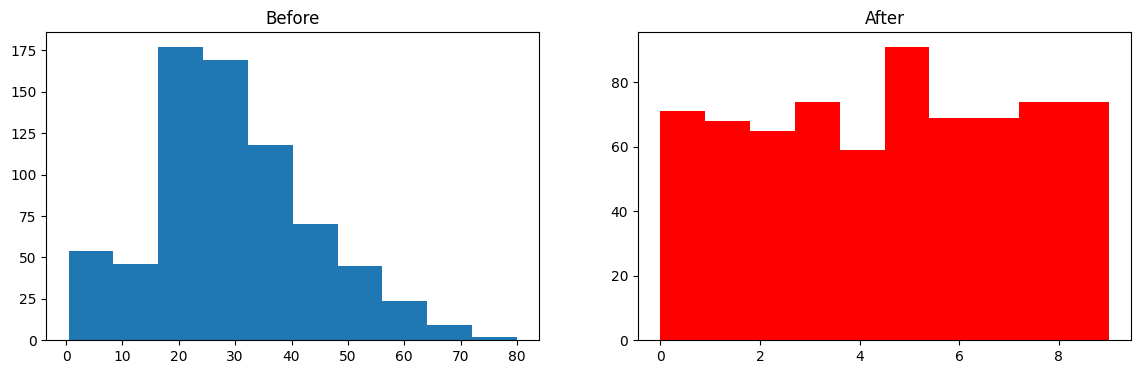

In [60]:
def discretize(bins, strategy):

    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])

    x_trf = trf.fit_transform(x)

    print(np.mean(cross_val_score(DecisionTreeClassifier(), x_trf, y, cv=10, scoring='accuracy')))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    plt.hist(x['Age'].values)
    plt.title("Before")

    plt.subplot(122)
    plt.hist(x_trf[:,0], color='red')
    plt.title("After")

    plt.show()


discretize(10, 'quantile')

c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\visha\OneDrive\Desktop\pandas\.venv\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


0.682140062597809


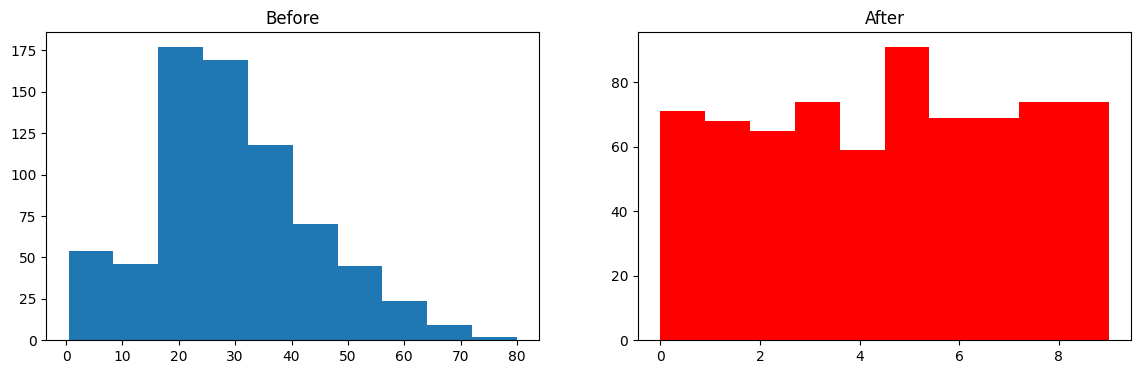

In [61]:
def discretize(bins, strategy):

    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])

    x_trf = trf.fit_transform(x)

    print(np.mean(cross_val_score(DecisionTreeClassifier(), x_trf, y, cv=10, scoring='accuracy')))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    plt.hist(x['Age'].values)
    plt.title("Before")

    plt.subplot(122)
    plt.hist(x_trf[:,0], color='red')
    plt.title("After")

    plt.show()


discretize(10, 'quantile')

In [62]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [63]:
df =pd.read_csv('titanic.csv')[['Age','Fare', 'SibSp', 'Parch', 'Survived']]

In [64]:
df.dropna(inplace=True)

In [65]:
df.head()

,Age,Fare,SibSp,Parch,Survived
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [66]:
df.shape

(714, 5)

In [67]:
df['family'] = df['SibSp'] + df['Parch']

In [68]:
df.head()

,Age,Fare,SibSp,Parch,Survived,family
0,22.0,7.2500,1,0,0,1
1,38.0,71.2833,1,0,1,1
2,26.0,7.9250,0,0,1,0
3,35.0,53.1000,1,0,1,1
4,35.0,8.0500,0,0,0,0


In [69]:
df.drop(columns=['SibSp', 'Parch'],inplace=True)

In [70]:
df.head()

,Age,Fare,Survived,family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [71]:
x = df.drop(columns = ['Survived'])
y = df['Survived']

In [72]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [73]:
x_train.head()

,Age,Fare,family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


# without binarization 

In [74]:
clf = DecisionTreeClassifier()

clf.fit(x_train, y_train)

y_pred = clf.predict(x_test)

accuracy_score(y_test, y_pred)

0.6223776223776224

In [75]:
np.mean(cross_val_score(DecisionTreeClassifier(), x, y, cv=10, scoring='accuracy'))

np.float64(0.6429381846635367)

# applying binarization 

In [76]:
from sklearn.preprocessing import Binarizer

In [81]:
from sklearn.preprocessing import Binarizer
from sklearn.compose import ColumnTransformer

trf = ColumnTransformer([
    ('bin', Binarizer(copy=False), ['family'])
], remainder='passthrough')

x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

In [82]:
pd.DataFrame(x_train_trf, columns=['family', 'Age', 'Fare'])

,family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [83]:
clf = DecisionTreeClassifier()
clf.fit(x_train_trf, y_train)
y_pred2 = clf.predict(x_test_trf)

accuracy_score(y_test, y_pred2)

0.6083916083916084

In [84]:
x_trf = trf.fit_transform(x)
np.mean(cross_val_score(DecisionTreeClassifier(), x_trf, y, cv=10, scoring='accuracy'))

np.float64(0.6219874804381847)